In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [5]:
data = pd.read_csv("temperatures.csv")

Enter year:  1990


JAN Temperature: 24.06 °C
MSE: 0.5567563295289465
MAE: 0.5083956669577453

FEB Temperature: 26.18 °C
MSE: 0.8244076743119072
MAE: 0.6321543551026766

MAR Temperature: 29.48 °C
MSE: 1.0139624850303435
MAE: 0.7784057105758042

APR Temperature: 32.35 °C
MSE: 0.7575254532219998
MAE: 0.6435124751370077

MAY Temperature: 33.82 °C
MSE: 0.45175723353377784
MAE: 0.5404967704413929

JUN Temperature: 32.94 °C
MSE: 0.38456134236372935
MAE: 0.49514306129104274

JUL Temperature: 31.24 °C
MSE: 0.22011797715964113
MAE: 0.3504556156873894

AUG Temperature: 30.79 °C
MSE: 0.18792782189800752
MAE: 0.34724741209320814

SEP Temperature: 30.8 °C
MSE: 0.0758692548530812
MAE: 0.20713528500102404

OCT Temperature: 30.15 °C
MSE: 0.5307840588165339
MAE: 0.5732150881636587

NOV Temperature: 27.68 °C
MSE: 0.4306612625830053
MAE: 0.4761664976562221

DEC Temperature: 25.07 °C
MSE: 0.49825939386703366
MAE: 0.4814995951587678

Overall MSE: 0.49438252393066723
Overall MAE: 0.502818961105495


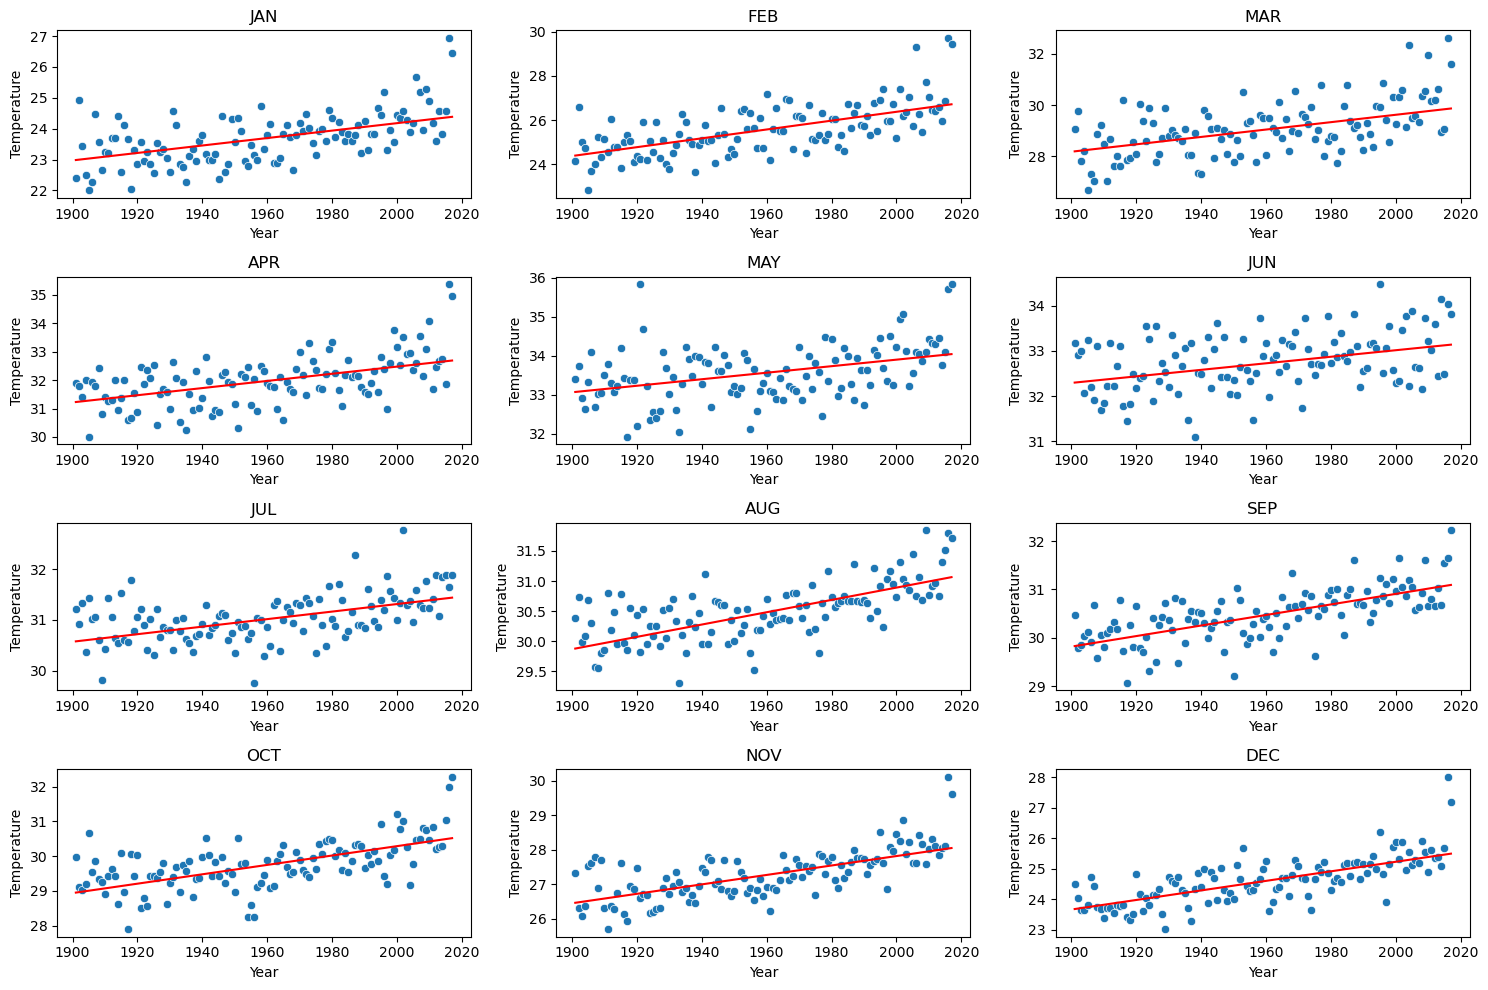

In [6]:
months = ['JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN',
          'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC']

X = data[['YEAR']]

year = int(input("Enter year: "))

actual = []
predicted = []

plt.figure(figsize=(15, 10))

for month in months:

    y = data[month]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    actual.extend(y_test)
    predicted.extend(y_pred)

    temp = model.predict(pd.DataFrame({'YEAR': [year]}))

    print(month, "Temperature:", round(temp[0], 2), "°C")
    print("MSE:", mean_squared_error(y_test, y_pred))
    print("MAE:", mean_absolute_error(y_test, y_pred))
    print()

    plt.subplot(4, 3, months.index(month) + 1)

    sns.scatterplot(x=X['YEAR'], y=y)
    sns.lineplot(x=X['YEAR'], y=model.predict(X), color='red')

    plt.title(month)
    plt.xlabel("Year")
    plt.ylabel("Temperature")

print("Overall MSE:", mean_squared_error(actual, predicted))
print("Overall MAE:", mean_absolute_error(actual, predicted))

plt.tight_layout()
plt.show()

In [3]:
df.head()

,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JAN-FEB,MAR-MAY,JUN-SEP,OCT-DEC
0,1901,22.40,24.14,29.07,31.91,33.41,33.18,31.21,30.39,30.47,29.97,27.31,24.49,28.96,23.27,31.46,31.27,27.25
1,1902,24.93,26.58,29.77,31.78,33.73,32.91,30.92,30.73,29.80,29.12,26.31,24.04,29.22,25.75,31.76,31.09,26.49
2,1903,23.44,25.03,27.83,31.39,32.91,33.00,31.34,29.98,29.85,29.04,26.08,23.65,28.47,24.24,30.71,30.92,26.26
3,1904,22.50,24.73,28.21,32.02,32.64,32.07,30.36,30.09,30.04,29.20,26.36,23.63,28.49,23.62,30.95,30.66,26.40
4,1905,22.00,22.83,26.68,30.01,33.32,33.25,31.44,30.68,30.12,30.67,27.52,23.82,28.30,22.25,30.00,31.33,26.57


In [13]:
print(df.shape)
df.describe()

(117, 18)


,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JAN-FEB,MAR-MAY,JUN-SEP,OCT-DEC
count,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000
mean,1959.000000,23.687436,25.597863,29.085983,31.975812,33.565299,32.774274,31.035897,30.507692,30.486752,29.766581,27.285470,24.608291,29.181368,24.629573,31.517607,31.198205,27.208120
std,33.919021,0.834588,1.150757,1.068451,0.889478,0.724905,0.633132,0.468818,0.476312,0.544295,0.705492,0.714518,0.782644,0.555555,0.911239,0.740585,0.420508,0.672003
min,1901.000000,22.000000,22.830000,26.680000,30.010000,31.930000,31.100000,29.760000,29.310000,29.070000,27.900000,25.700000,23.020000,28.110000,22.250000,29.920000,30.240000,25.740000
25%,1930.000000,23.100000,24.780000,28.370000,31.460000,33.110000,32.340000,30.740000,30.180000,30.120000,29.380000,26.790000,24.040000,28.760000,24.110000,31.040000,30.920000,26.700000
50%,1959.000000,23.680000,25.480000,29.040000,31.950000,33.510000,32.730000,31.000000,30.540000,30.520000,29.780000,27.300000,24.660000,29.090000,24.530000,31.470000,31.190000,27.210000
75%,1988.000000,24.180000,26.310000,29.610000,32.420000,34.030000,33.180000,31.330000,30.760000,30.810000,30.170000,27.720000,25.110000,29.470000,25.150000,31.890000,31.400000,27.610000
max,2017.000000,26.940000,29.720000,32.620000,35.380000,35.840000,34.480000,32.760000,31.840000,32.220000,32.290000,30.110000,28.010000,31.630000,28.330000,34.570000,32.410000,30.030000


In [29]:
months = ['JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN',
          'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC']

# Check missing values

print("Missing values before handling:")
print(df[months].isnull().sum())
print(df[months].describe())

Missing values before handling:
JAN    0
FEB    0
MAR    0
APR    0
MAY    0
JUN    0
JUL    0
AUG    0
SEP    0
OCT    0
NOV    0
DEC    0
dtype: int64
              JAN         FEB         MAR         APR         MAY         JUN  \
count  117.000000  117.000000  117.000000  117.000000  117.000000  117.000000   
mean    23.687436   25.597863   29.085983   31.975812   33.565299   32.774274   
std      0.834588    1.150757    1.068451    0.889478    0.724905    0.633132   
min     22.000000   22.830000   26.680000   30.010000   31.930000   31.100000   
25%     23.100000   24.780000   28.370000   31.460000   33.110000   32.340000   
50%     23.680000   25.480000   29.040000   31.950000   33.510000   32.730000   
75%     24.180000   26.310000   29.610000   32.420000   34.030000   33.180000   
max     26.940000   29.720000   32.620000   35.380000   35.840000   34.480000   

              JUL         AUG         SEP         OCT         NOV         DEC  
count  117.000000  117.000000  117.00

In [19]:

monthly_avg = df[months].mean()
monthly_avg

JAN    23.687436
FEB    25.597863
MAR    29.085983
APR    31.975812
MAY    33.565299
JUN    32.774274
JUL    31.035897
AUG    30.507692
SEP    30.486752
OCT    29.766581
NOV    27.285470
DEC    24.608291
dtype: float64

In [24]:
data = pd.DataFrame({
    'Month': range(1, 13),
    'Temperature': monthly_avg
})

data

,Month,Temperature
JAN,1,23.687436
FEB,2,25.597863
MAR,3,29.085983
APR,4,31.975812
MAY,5,33.565299
JUN,6,32.774274
JUL,7,31.035897
AUG,8,30.507692
SEP,9,30.486752
OCT,10,29.766581


In [62]:
X = pd.DataFrame()

X['Month_sin'] = np.sin(2 * np.pi * (data['Month'] - 1) / 12)
X['Month_cos'] = np.cos(2 * np.pi * (data['Month'] - 1) / 12)

y = data['Temperature']

In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [64]:
model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[ 2.14,-3.67]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['Month_sin','Month_cos']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,28.9
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [69]:
predictions = model.predict(X)
data['Predicted_Temperature'] = predictions
data

,Month,Temperature,Predicted_Temperature
JAN,1,23.687436,25.237986
FEB,2,25.597863,26.801014
MAR,3,29.085983,28.927605
APR,4,31.975812,31.047938
MAY,5,33.565299,32.593874
JUN,6,32.774274,33.151179
JUL,7,31.035897,32.570524
AUG,8,30.507692,31.007495
SEP,9,30.486752,28.880904
OCT,10,29.766581,26.760571


In [71]:
y_pred = model.predict(X_test)
y_pred

array([25.21463539, 26.76057068, 25.23798564])

In [72]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

In [73]:
print("Model Performance:")
print("MSE:", mse)
print("MAE:", mae)
print("R2 Score:", r2)

Model Performance:
MSE: 5.2428866939862795
MAE: 2.209131652577163
R2 Score: 0.15826155226898564


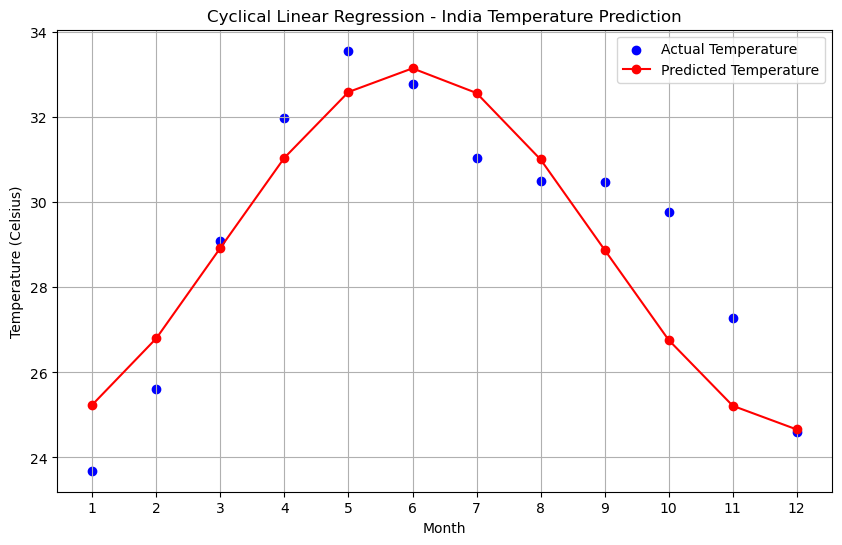

In [75]:
plt.figure(figsize=(10, 6))

plt.scatter(data['Month'], y, color='blue', label='Actual Temperature')
plt.plot(data['Month'], model.predict(X), color='red',
         marker='o', label='Predicted Temperature')

plt.xlabel("Month")
plt.ylabel("Temperature (Celsius)")
plt.title("Cyclical Linear Regression - India Temperature Prediction")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True)
plt.show()
